# 02 · Inferential Hypothesis Testing
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KrishKamra/Customer_Churn_Prediction/blob/main/notebooks/02_inferential_statistics.ipynb)

Which differences between churners and retained customers are **statistically real**?

1. **Continuous:** Welch's t-test (unequal variances) + Mann-Whitney U (rank-based).
2. **Categorical:** χ² test of independence across all 16 categorical variables, with
   bias-corrected **Cramér's V** effect sizes.
3. **Synthesis:** a Markdown report written to `docs/evaluations/statistical_report.md`.

All computations live in `src/analytics/statistics.py`, so the dashboard's *Evidence* tab
shows exactly the same numbers.

> **Runtime:** CPU (default). SciPy tests on 7k rows run in milliseconds.

In [1]:
# ⚙️ Environment bootstrap — identical on Google Colab and locally.
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/KrishKamra/Customer_Churn_Prediction.git"

if IN_COLAB:
    ROOT = Path("/content/Customer_Churn_Prediction")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)
    # uv resolves in seconds and keeps Colab's preinstalled, compatible wheels.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
    subprocess.run(["uv", "pip", "install", "--system", "-q", "-e", ".[notebooks]"], check=True)
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | Colab: {IN_COLAB}")

Project root: C:\Users\krish\workspace\archive\Customer_Churn_Prediction | Colab: False


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from src.analytics.plotting import PALETTE, apply_theme, save
from src.analytics.statistics import (
    ALPHA,
    CATEGORICAL_TEST_COLUMNS,
    chi_square_suite,
    continuous_tests,
    render_statistical_report,
    with_log_total,
)
from src.config import get_settings
from src.features.engineer import load_clean

apply_theme()
settings = get_settings()
df = load_clean()
print(f"{len(df):,} customers · churn rate {df['Churn'].mean():.2%} · α = {ALPHA}")

7,043 customers · churn rate 26.54% · α = 0.05


## 1 · Assumption checks

In [3]:
data = with_log_total(df)
rows = []
for col in ["tenure", "MonthlyCharges", "TotalCharges_log"]:
    for label, grp in data.groupby("Churn")[col]:
        sample = grp.sample(min(len(grp), 500), random_state=0)
        rows.append(
            {
                "feature": col,
                "churn": label,
                "shapiro_p": stats.shapiro(sample).pvalue,
                "variance": grp.var(),
            }
        )
assumptions = pd.DataFrame(rows)
levene = {
    c: stats.levene(*[g for _, g in data.groupby("Churn")[c]]).pvalue
    for c in ["tenure", "MonthlyCharges", "TotalCharges_log"]
}
display(assumptions)
print("Levene p (equal variances):", {k: f"{v:.2e}" for k, v in levene.items()})

,feature,churn,shapiro_p,variance
0,tenure,0,5.765588e-16,581.474226
1,tenure,1,2.103207e-23,381.464768
2,MonthlyCharges,0,4.025192e-16,966.752767
3,MonthlyCharges,1,1.503099e-14,608.414183
4,TotalCharges_log,0,1.329054e-15,2.191175
5,TotalCharges_log,1,1.558795e-12,2.708550


Levene p (equal variances): {'tenure': '3.96e-90', 'MonthlyCharges': '1.03e-78', 'TotalCharges_log': '7.94e-25'}


Every group fails Shapiro-Wilk normality and Levene's equal-variance test. Hence:
**Welch's** t-test (no equal-variance assumption; robust to non-normality at n > 1,800 by the
CLT) paired with the distribution-free **Mann-Whitney U** as a cross-check.

## 2 · Continuous variables

In [4]:
cont = continuous_tests(df)
cont.style.format(
    {
        "welch_p": "{:.2e}",
        "mannwhitney_p": "{:.2e}",
        "mean_churned": "{:,.2f}",
        "mean_retained": "{:,.2f}",
        "welch_t": "{:.2f}",
        "rank_biserial": "{:+.3f}",
        "cohens_d": "{:+.3f}",
    },
    precision=2,
)

,feature,mean_churned,mean_retained,median_churned,median_retained,welch_t,welch_p,mannwhitney_u,mannwhitney_p,rank_biserial,cohens_d,skew_churned,skew_retained
0,tenure,17.98,37.57,10.00,38.00,-34.82,1.20e-232,2515538.00,2.42e-208,+0.480,-0.852,1.15,-0.03
1,MonthlyCharges,74.44,61.27,79.65,64.43,18.41,8.59e-73,6003125.50,3.31e-54,-0.242,+0.446,-0.73,-0.03
2,TotalCharges_log,6.32,7.15,6.56,7.43,-19.22,9.77e-78,3381224.00,5.69e-83,+0.301,-0.545,-0.25,-1.09


In [5]:
row = cont.set_index("feature").loc["TotalCharges_log"]
print(f"Welch's t-test on log1p(TotalCharges): t = {row.welch_t:.2f}, p = {row.welch_p:.3e}")
print(f"Mann-Whitney U on log1p(TotalCharges): p = {row.mannwhitney_p:.3e}")
assert (cont["welch_p"] < ALPHA).all() and (cont["mannwhitney_p"] < ALPHA).all()

Welch's t-test on log1p(TotalCharges): t = -19.22, p = 9.774e-78
Mann-Whitney U on log1p(TotalCharges): p = 5.685e-83


## 3 · Categorical association suite (χ² + Cramér's V)

In [6]:
assert len(CATEGORICAL_TEST_COLUMNS) == 16
chi = chi_square_suite(df)
# Bonferroni control of the family-wise error rate across the 16 tests.
chi["significant_bonferroni"] = chi["p_value"] < ALPHA / len(chi)
chi.style.format(
    {"chi2": "{:,.1f}", "p_value": "{:.2e}", "cramers_v": "{:.3f}", "highest_risk_rate": "{:.1%}"}
)

,feature,chi2,dof,p_value,cramers_v,significant,highest_risk_level,highest_risk_rate,significant_bonferroni
0,Contract,"1,184.6",2,5.86e-258,0.410,True,Month-to-month,42.7%,True
1,OnlineSecurity,850.0,2,2.66e-185,0.347,True,No,41.8%,True
2,TechSupport,828.2,2,1.44e-180,0.343,True,No,41.6%,True
3,InternetService,732.3,2,9.57e-160,0.322,True,Fiber optic,41.9%,True
4,PaymentMethod,648.1,3,3.68e-140,0.303,True,Electronic check,45.3%,True
5,OnlineBackup,601.8,2,2.08e-131,0.292,True,No,39.9%,True
6,DeviceProtection,558.4,2,5.51e-122,0.281,True,No,39.1%,True
7,StreamingMovies,375.7,2,2.67e-82,0.230,True,No,33.7%,True
8,StreamingTV,374.2,2,5.53e-82,0.230,True,No,33.5%,True
9,PaperlessBilling,259.2,1,2.61e-58,0.191,True,Yes,33.6%,True


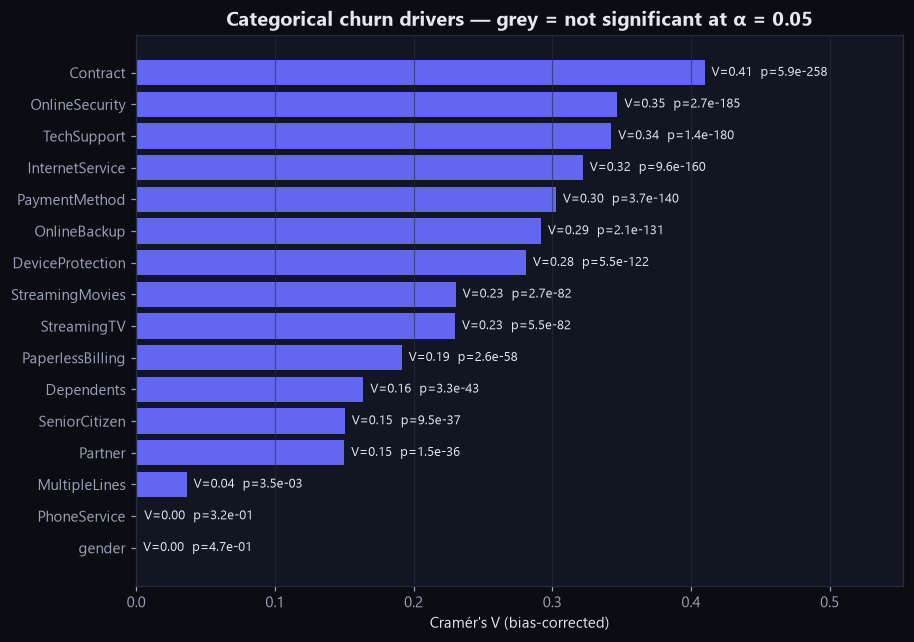

In [7]:
fig, ax = plt.subplots(figsize=(9, 6.5))
order = chi.sort_values("cramers_v")
colors = [PALETTE["violet"] if s else PALETTE["muted"] for s in order["significant"]]
ax.barh(order["feature"], order["cramers_v"], color=colors)
for y, (v, p) in enumerate(zip(order["cramers_v"], order["p_value"], strict=True)):
    ax.text(v + 0.005, y, f"V={v:.2f}  p={p:.1e}", va="center", fontsize=8.5)
ax.set_xlim(0, order["cramers_v"].max() * 1.35)
ax.set_xlabel("Cramér's V (bias-corrected)")
ax.set_title("Categorical churn drivers — grey = not significant at α = 0.05")
ax.grid(axis="y", visible=False)
save(fig, settings.figures_dir / "cramers_v_ranking.png");

In [8]:
top = chi.iloc[0]
g = chi.set_index("feature")
print(f"Primary driver: {top.feature} (V = {top.cramers_v:.3f}, p = {top.p_value:.2e})")
print(f"gender: p = {g.loc['gender', 'p_value']:.3f} → independent of churn")
print(f"PhoneService: p = {g.loc['PhoneService', 'p_value']:.3f} → independent of churn")
assert top.feature == "Contract"
assert not g.loc["gender", "significant"] and not g.loc["PhoneService", "significant"]
pd.crosstab(df["Contract"], df["Churn"], margins=True)

Primary driver: Contract (V = 0.410, p = 5.86e-258)
gender: p = 0.470 → independent of churn
PhoneService: p = 0.316 → independent of churn


Churn,0,1,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


**Fairness note.** `gender` is statistically independent of churn (χ² p ≈ 0.47, V ≈ 0). It
stays in the feature set for transparency, but carries ~zero signal — see the model card.

## 4 · Synthesis report

In [9]:
report = render_statistical_report(df)
out = settings.evaluations_dir / "statistical_report.md"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(report, encoding="utf-8")
print(f"✅ wrote {out.relative_to(ROOT)} ({len(report.splitlines())} lines)")

✅ wrote docs\evaluations\statistical_report.md (63 lines)


In [10]:
from IPython.display import Markdown

Markdown(report)

# Statistical Report — Inferential Evidence

> Auto-generated by `notebooks/02_inferential_statistics.ipynb` via `src.analytics.statistics.render_statistical_report`.  
> Generated: `2026-11-02 16:02 UTC` · n = 7,043 customers · churn rate = 26.54% · α = 0.05

## 1. Continuous variables: churned vs. retained

Welch's t-test (unequal variances) tests mean differences; the Mann-Whitney U test is the distribution-free check, which matters because `tenure` and `TotalCharges` are strongly skewed.

| Feature | Mean (churned) | Mean (retained) | Welch t | Welch p | Mann-Whitney p | Rank-biserial r | Cohen's d |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| `tenure` | 17.98 | 37.57 | -34.82 | 1.20e-232 | 2.42e-208 | +0.480 | -0.852 |
| `MonthlyCharges` | 74.44 | 61.27 | 18.41 | 8.59e-73 | 3.31e-54 | -0.242 | +0.446 |
| `TotalCharges_log` | 6.32 | 7.15 | -19.22 | 9.77e-78 | 5.69e-83 | +0.301 | -0.545 |

**Interpretation.** Churners have markedly shorter tenure and lower lifetime spend but *higher* monthly charges: they are new, expensive-plan customers. Both the parametric and rank-based tests agree for every variable.

## 2. Collinearity of financial variables (Pearson r)

| | tenure | MonthlyCharges | TotalCharges |
| :--- | ---: | ---: | ---: |
| `tenure` | 1.000 | 0.248 | 0.826 |
| `MonthlyCharges` | 0.248 | 1.000 | 0.651 |
| `TotalCharges` | 0.826 | 0.651 | 1.000 |

`TotalCharges` is close to `tenure × MonthlyCharges` (r = 0.83 with tenure), so the pipeline adds a charge-velocity ratio instead of relying on the redundant raw total.

## 3. Categorical association suite (χ² test of independence + Cramér's V)

Cramér's V is bias-corrected (Bergsma, 2013). Rough guide for this table size: 0.1 small, 0.3 medium, 0.5 large.

| Rank | Feature | χ² | dof | p-value | Cramér's V | Significant | Highest-risk level (churn rate) |
| ---: | :--- | ---: | ---: | ---: | ---: | :---: | :--- |
| 1 | `Contract` | 1,184.6 | 2 | 5.86e-258 | 0.410 | ✅ | Month-to-month (42.7%) |
| 2 | `OnlineSecurity` | 850.0 | 2 | 2.66e-185 | 0.347 | ✅ | No (41.8%) |
| 3 | `TechSupport` | 828.2 | 2 | 1.44e-180 | 0.343 | ✅ | No (41.6%) |
| 4 | `InternetService` | 732.3 | 2 | 9.57e-160 | 0.322 | ✅ | Fiber optic (41.9%) |
| 5 | `PaymentMethod` | 648.1 | 3 | 3.68e-140 | 0.303 | ✅ | Electronic check (45.3%) |
| 6 | `OnlineBackup` | 601.8 | 2 | 2.08e-131 | 0.292 | ✅ | No (39.9%) |
| 7 | `DeviceProtection` | 558.4 | 2 | 5.51e-122 | 0.281 | ✅ | No (39.1%) |
| 8 | `StreamingMovies` | 375.7 | 2 | 2.67e-82 | 0.230 | ✅ | No (33.7%) |
| 9 | `StreamingTV` | 374.2 | 2 | 5.53e-82 | 0.230 | ✅ | No (33.5%) |
| 10 | `PaperlessBilling` | 259.2 | 1 | 2.61e-58 | 0.191 | ✅ | Yes (33.6%) |
| 11 | `Dependents` | 189.9 | 1 | 3.28e-43 | 0.164 | ✅ | No (31.3%) |
| 12 | `SeniorCitizen` | 160.4 | 1 | 9.48e-37 | 0.150 | ✅ | 1 (41.7%) |
| 13 | `Partner` | 159.4 | 1 | 1.52e-36 | 0.150 | ✅ | No (33.0%) |
| 14 | `MultipleLines` | 11.3 | 2 | 0.0035 | 0.036 | ✅ | Yes (28.6%) |
| 15 | `PhoneService` | 1.0 | 1 | 0.3162 | 0.001 | ❌ | Yes (26.7%) |
| 16 | `gender` | 0.5 | 1 | 0.4698 | 0.000 | ❌ | Female (26.9%) |

**Interpretation.** `Contract` is the strongest categorical driver (V = 0.410). Not significant at α = 0.05: `PhoneService`, `gender`. Gender independence from churn is the key fairness result used in the model card.

## 4. Tenure cohorts — the danger zone

| Cohort | Customers | Churn rate |
| :--- | ---: | ---: |
| 0-6m 🚨 | 1,481 | 52.9% |
| 7-12m | 705 | 35.9% |
| 1-2y | 1,024 | 28.7% |
| 2-4y | 1,594 | 20.4% |
| 4y+ | 2,239 | 9.5% |

Over half of customers in their first six months churn — retention spend should be front-loaded into onboarding.


In [11]:
# 📦 Colab only: bundle generated artifacts for download (Colab disks are ephemeral).
if IN_COLAB:
    import shutil

    from google.colab import files

    stage = Path("/content/churnai_stats")
    shutil.rmtree(stage, ignore_errors=True)
    for sub in (
        "docs/evaluations",
        "docs/figures",
    ):
        if (ROOT / sub).exists():
            shutil.copytree(ROOT / sub, stage / sub)
    files.download(shutil.make_archive(str(stage), "zip", stage))
    print("Unzip over your local clone and commit to publish the artifacts.")
else:
    print("Running locally — artifacts are already written into the repository.")

Running locally — artifacts are already written into the repository.
